In [1]:
import pandas as pd
import re

In [2]:
f = open('WhatsApp Chat with AllStudents@RECB_official.txt','r',encoding = 'utf-8')

In [3]:
data = f.read()

In [4]:
data

'27/04/26, 14:42 - Messages and calls are end-to-end encrypted. Only people in this chat can read, listen to, or share them. *Learn more*\n14/01/23, 06:55 - Suneel Sir ( Aarden BH4) created group "AllStudents@RECB_official"\n30/04/26, 12:14 - Dr. Er Mohhamad Rec: Urgent Reminder!!!\nThose who still have not filled the exam form are instructed to do it on an urgent basis, as today is the last date.\nFor any upcoming issues, contact the dean office immediately.\n30/04/26, 18:35 - Dr. Er Mohhamad Rec: <Media omitted>\n30/04/26, 18:51 - Santosh Sir: <Media omitted>\n30/04/26, 19:03 - Santosh Sir: *Date: 1 May 2026*\n01/05/26, 21:53 - Dr. Er Mohhamad Rec: <Media omitted>\n02/05/26, 12:28 - Suneel Sir ( Aarden BH4): <Media omitted>\n02/05/26, 12:28 - Suneel Sir ( Aarden BH4): Dear All,\n\nWe have published the College Round results (Top 3 students from each of the eligible colleges) on our website:\nhttps://nflq.nism.ac.in/resultCollegeRound\n\nAn official communication will also be sent to 

In [5]:
pattern = '\d{1,2}/\d{1,2}/\d{2,4},\s\d{1,2}:\d{2}\s-'

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\numan\AppData\Local\Temp\ipykernel_13380\486551751.py:1: SyntaxWarning: invalid escape sequence '\d'
  pattern = '\d{1,2}/\d{1,2}/\d{2,4},\s\d{1,2}:\d{2}\s-'


In [6]:
messages = re.split(pattern,data)[1:]
len(messages)

550

In [7]:
dates = re.findall(pattern, data)
dates

['27/04/26, 14:42 -',
 '14/01/23, 06:55 -',
 '30/04/26, 12:14 -',
 '30/04/26, 18:35 -',
 '30/04/26, 18:51 -',
 '30/04/26, 19:03 -',
 '01/05/26, 21:53 -',
 '02/05/26, 12:28 -',
 '02/05/26, 12:28 -',
 '02/05/26, 14:29 -',
 '02/05/26, 15:50 -',
 '03/05/26, 11:56 -',
 '03/05/26, 16:02 -',
 '03/05/26, 19:32 -',
 '06/05/26, 16:34 -',
 '06/05/26, 16:34 -',
 '06/05/26, 16:37 -',
 '06/05/26, 16:57 -',
 '06/05/26, 17:13 -',
 '07/05/26, 09:52 -',
 '07/05/26, 09:52 -',
 '07/05/26, 17:00 -',
 '10/05/26, 20:51 -',
 '11/05/26, 20:01 -',
 '13/05/26, 10:30 -',
 '13/05/26, 14:18 -',
 '13/05/26, 14:20 -',
 '14/05/26, 11:18 -',
 '14/05/26, 17:26 -',
 '19/05/26, 16:25 -',
 '23/05/26, 09:53 -',
 '23/05/26, 21:30 -',
 '25/05/26, 13:55 -',
 '26/05/26, 17:30 -',
 '26/05/26, 18:46 -',
 '26/05/26, 20:17 -',
 '28/05/26, 08:13 -',
 '02/06/26, 21:07 -',
 '05/06/26, 13:34 -',
 '05/06/26, 13:34 -',
 '08/06/26, 17:21 -',
 '08/06/26, 18:44 -',
 '09/06/26, 15:49 -',
 '13/06/26, 10:30 -',
 '17/06/26, 21:42 -',
 '17/06/26

In [8]:
df = pd.DataFrame({'user_message' :messages, 'message_date' : dates})

df['message_date'] = pd.to_datetime(df['message_date'], format='%d/%m/%y, %H:%M -')

df.rename(columns = {'message_date' : 'date'}, inplace = True)

df.head(1
       )

,user_message,date
0,Messages and calls are end-to-end encrypted. ...,2026-04-27 14:42:00


In [9]:
df.iloc[45][0]

C:\Users\numan\AppData\Local\Temp\ipykernel_13380\2852532987.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df.iloc[45][0]


' Dr. Er Mohhamad Rec: <Media omitted>\n'

In [10]:
# seperate user and messages

users = []
messages = []

for message in df['user_message']:
    entry = re.split('([\w\W]+?):\s',message)
    if entry[1:]:
        users.append(entry[1])
        messages.append(entry[2])
    else:
        users.append('group_notification')
        messages.append(entry[0])

df['user'] = users
df['message'] = messages
df.drop(columns = ['user_message'], inplace = True)

df.head()

<>:7: SyntaxWarning: invalid escape sequence '\w'
<>:7: SyntaxWarning: invalid escape sequence '\w'
C:\Users\numan\AppData\Local\Temp\ipykernel_13380\3821533725.py:7: SyntaxWarning: invalid escape sequence '\w'
  entry = re.split('([\w\W]+?):\s',message)


,date,user,message
0,2026-04-27 14:42:00,group_notification,Messages and calls are end-to-end encrypted. ...
1,2023-01-14 06:55:00,group_notification,"Suneel Sir ( Aarden BH4) created group ""AllSt..."
2,2026-04-30 12:14:00,Dr. Er Mohhamad Rec,Urgent Reminder!!!\nThose who still have not f...
3,2026-04-30 18:35:00,Dr. Er Mohhamad Rec,<Media omitted>\n
4,2026-04-30 18:51:00,Santosh Sir,<Media omitted>\n


## extract year,month and all from date

In [11]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month_name()
df['day'] = df['date'].dt.day

In [12]:
df.head()

,date,user,message,year,month,day
0,2026-04-27 14:42:00,group_notification,Messages and calls are end-to-end encrypted. ...,2026,April,27
1,2023-01-14 06:55:00,group_notification,"Suneel Sir ( Aarden BH4) created group ""AllSt...",2023,January,14
2,2026-04-30 12:14:00,Dr. Er Mohhamad Rec,Urgent Reminder!!!\nThose who still have not f...,2026,April,30
3,2026-04-30 18:35:00,Dr. Er Mohhamad Rec,<Media omitted>\n,2026,April,30
4,2026-04-30 18:51:00,Santosh Sir,<Media omitted>\n,2026,April,30


In [13]:
df['hour'] = df['date'].dt.hour
df['minutes'] = df['date'].dt.minute
df['second'] = df['date'].dt.second

In [14]:
df['second'] = df['date'].dt.second

In [15]:
df.head()

,date,user,message,year,month,day,hour,minutes,second
0,2026-04-27 14:42:00,group_notification,Messages and calls are end-to-end encrypted. ...,2026,April,27,14,42,0
1,2023-01-14 06:55:00,group_notification,"Suneel Sir ( Aarden BH4) created group ""AllSt...",2023,January,14,6,55,0
2,2026-04-30 12:14:00,Dr. Er Mohhamad Rec,Urgent Reminder!!!\nThose who still have not f...,2026,April,30,12,14,0
3,2026-04-30 18:35:00,Dr. Er Mohhamad Rec,<Media omitted>\n,2026,April,30,18,35,0
4,2026-04-30 18:51:00,Santosh Sir,<Media omitted>\n,2026,April,30,18,51,0


## APP functions

In [16]:
# check for particular user then size of msg 
df[df['user'] == 'Dr. Er Mohhamad Rec'].shape[0]
    

0

In [17]:
#check for words in msg
words_list = []
for msg in df['message']:
    words_list.extend(msg.split())
len(words_list)

4610

In [18]:
words_list = []
for msg in df['message']:
    words_list.append(msg.split())
len(words_list)

550

In [19]:
count = 0
pattern = r'<Media omitted>\n'
for msg in df['message']:
    if re.search(pattern, msg):
        count +=1

In [20]:
count

199

In [21]:
from urlextract import URLExtract
links = []
extractor = URLExtract()
for msg in df['message']:
   found = extractor.find_urls(msg)

   if found :
        links.extend(found)
# link.remove('[]')
    
    

In [22]:
# !pip install urlextract

In [23]:
links

['https://docs.google.com/forms/d/e/1FAIpQLScuuAIxn-JoZnc7jq1b2P4cK362Wtcn7ZiESW723ncOA2cUSg/viewform?usp=publish-editor',
 'https://forms.gle/2851RyKfhLrTvoiJA',
 'https://docs.google.com/forms/d/e/1FAIpQLSdkZ_5OGIniJ1LwKw3Jf9KHcPzHLV5KErBePFfZQjproUG0AQ/viewform?usp=dialog',
 'https://forms.gle/7fvH7irqspqZ1xtn9',
 'https://docs.google.com/forms/d/1-w_Q7f8eyUQ-Lm93vY2dBKVr6sfTXbGQVLqShmFWock/viewform?pli=1&pli=1&edit_requested=true',
 'https://www.instagram.com/raise_recbijnor?stkn=MTVlZWJtOXB0b253cQ%3D%3D&utm_source=qr',
 'https://www.linkedin.com/posts/rajkiya-engineering-college-bijnor_sih2026-smartindiahackathon-recbijnor-activity-7508174212356882432-tOWJ?utm_source=share&utm_medium=member_android&rcm=ACoAAAET2KoBh4I351XifqB_8ABnR-EHZVJUg7w',
 'https://www.instagram.com/p/DdmAJ4gAbFh/?stkn=MTFmNDlkdThnM2hxdw==',
 'https://www.instagram.com/p/Dd22w4fgZhd/?img_index=7&stkn=MWtubGNvZ3ZzNnc1eg==',
 'https://nashamukt.dosje.gov.in/epledge?utm_source=chatgpt.com',
 'https://forms.gle/F

In [24]:
df.head()

,date,user,message,year,month,day,hour,minutes,second
0,2026-04-27 14:42:00,group_notification,Messages and calls are end-to-end encrypted. ...,2026,April,27,14,42,0
1,2023-01-14 06:55:00,group_notification,"Suneel Sir ( Aarden BH4) created group ""AllSt...",2023,January,14,6,55,0
2,2026-04-30 12:14:00,Dr. Er Mohhamad Rec,Urgent Reminder!!!\nThose who still have not f...,2026,April,30,12,14,0
3,2026-04-30 18:35:00,Dr. Er Mohhamad Rec,<Media omitted>\n,2026,April,30,18,35,0
4,2026-04-30 18:51:00,Santosh Sir,<Media omitted>\n,2026,April,30,18,51,0


In [25]:
# busiest users (top 5)

x = df[df['user'] != 'group_notification']['user'].value_counts().head(5)
    

In [26]:
name = x.index
count = x.values

In [27]:
count

array([52, 43, 42, 40, 23])

In [28]:
name

Index([' +91 63952 52445', ' Suneel Sir ( Aarden BH4)', ' Santosh Sir',
       ' Dr. Er Mohhamad Rec', ' +91 79068 35133'],
      dtype='object', name='user')

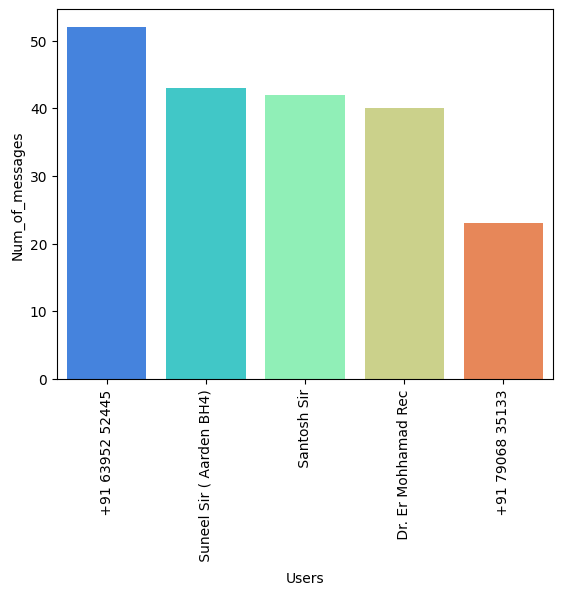

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.barplot(x=name, y=count, palette='rainbow', hue=name, legend=False)
plt.xticks(rotation = 'vertical')
plt.xlabel('Users')
plt.ylabel('Num_of_messages')
plt.show()

In [30]:
x = df['user'].value_counts()

names = x.index
counts = x.values

percentage = [round(val/sum(counts)* 100,2) for val in counts]

per_analyze = pd.DataFrame({
    'Name': names,
    'Message Count': counts,
    'Percentage': [str(p) + '%' for p in percentage]
})

In [31]:
per_analyze

,Name,Message Count,Percentage
0,group_notification,223,40.55%
1,+91 63952 52445,52,9.45%
2,Suneel Sir ( Aarden BH4),43,7.82%
3,Santosh Sir,42,7.64%
4,Dr. Er Mohhamad Rec,40,7.27%
5,+91 79068 35133,23,4.18%
6,Ishan Sir IT(HOD) Rec bijnor,17,3.09%
7,+91 97606 66466,17,3.09%
8,+91 77019 44129,17,3.09%
9,+91 98960 20767,14,2.55%


In [32]:
#top 25% used words in group as well as individual
#do filteration
#remove group_notification
#remove media count msg
#remove stop words
#then go


#remove group_noti and media count
temp = df[df['user'] != 'group_notification']
temp = temp[temp['message'] != '<Media omitted>\n']

#open stopwords
with open('Hinglish_stopwords.txt','r') as f:
    stop_words = f.read().splitlines()


words = []
for msg in temp['message']:
    for word in msg.lower().split():
        if word not in stop_words:
            words.append(word)


In [36]:
from collections import Counter
new_df = pd.DataFrame(Counter(words).most_common(50))




In [41]:
new_df = new_df.rename(columns = {
    0 : 'Messages',
    1: 'No_of_messages'
})

In [42]:
new_df

,Messages,No_of_messages
0,students,37
1,message,25
2,के,24
3,form,23
4,scholarship,22
5,से,22
6,में,17
7,deleted,16
8,year,16
9,को,14


In [48]:
import emoji

emojis = []

for msg in df['message'].dropna():
    emojis.extend([c for c in msg if c in emoji.EMOJI_DATA])

emoji_df = pd.DataFrame(
    Counter(emojis).most_common(),
    columns=['Emoji', 'Count']
)

print(emoji_df)

   Emoji  Count
0      ✨      4
1      🏆      2
2      🙏      2
3      🏻      2
4      📢      2
5      🔥      1
6      💪      1
7      🏅      1
8      🏸      1
9      🏐      1
10     🏏      1
11     🏓      1
12     ♟      1
13     ⚽      1
14     ❤      1


In [45]:
# !pip install emoji


   ---------------------------------------- 0.0/610.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/610.9 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/610.9 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/610.9 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/610.9 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/610.9 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/610.9 kB ? eta -:--:--
   -------------------------------- ----- 524.3/610.9 kB 265.9 kB/s eta 0:00:01
   ---------------------------------------- 610.9/610.9 kB 303.9 kB/s  0:00:01



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Time based analysis

In [49]:
df.head()

,date,user,message,year,month,day,hour,minutes,second
0,2026-04-27 14:42:00,group_notification,Messages and calls are end-to-end encrypted. ...,2026,April,27,14,42,0
1,2023-01-14 06:55:00,group_notification,"Suneel Sir ( Aarden BH4) created group ""AllSt...",2023,January,14,6,55,0
2,2026-04-30 12:14:00,Dr. Er Mohhamad Rec,Urgent Reminder!!!\nThose who still have not f...,2026,April,30,12,14,0
3,2026-04-30 18:35:00,Dr. Er Mohhamad Rec,<Media omitted>\n,2026,April,30,18,35,0
4,2026-04-30 18:51:00,Santosh Sir,<Media omitted>\n,2026,April,30,18,51,0


In [50]:
df['months_num'] = df['date'].dt.month

In [51]:
df.head()

,date,user,message,year,month,day,hour,minutes,second,months_num
0,2026-04-27 14:42:00,group_notification,Messages and calls are end-to-end encrypted. ...,2026,April,27,14,42,0,4
1,2023-01-14 06:55:00,group_notification,"Suneel Sir ( Aarden BH4) created group ""AllSt...",2023,January,14,6,55,0,1
2,2026-04-30 12:14:00,Dr. Er Mohhamad Rec,Urgent Reminder!!!\nThose who still have not f...,2026,April,30,12,14,0,4
3,2026-04-30 18:35:00,Dr. Er Mohhamad Rec,<Media omitted>\n,2026,April,30,18,35,0,4
4,2026-04-30 18:51:00,Santosh Sir,<Media omitted>\n,2026,April,30,18,51,0,4


In [64]:
timeline =df.groupby(['year','months_num','month']).count()['message'].reset_index()
timeline

,year,months_num,month,message
0,2023,1,January,1
1,2026,4,April,5
2,2026,5,May,31
3,2026,6,June,14
4,2026,7,July,32
5,2026,8,August,39
6,2026,9,September,256
7,2026,10,October,172


In [66]:
time = []

for i in range(timeline.shape[0]):
    time.append(timeline['month'][i] + "-" + str(timeline['year'][i]))

In [86]:
timeline['time'] = time
timeline

,year,months_num,month,message,time
0,2023,1,January,1,January-2023
1,2026,4,April,5,April-2026
2,2026,5,May,31,May-2026
3,2026,6,June,14,June-2026
4,2026,7,July,32,July-2026
5,2026,8,August,39,August-2026
6,2026,9,September,256,September-2026
7,2026,10,October,172,October-2026


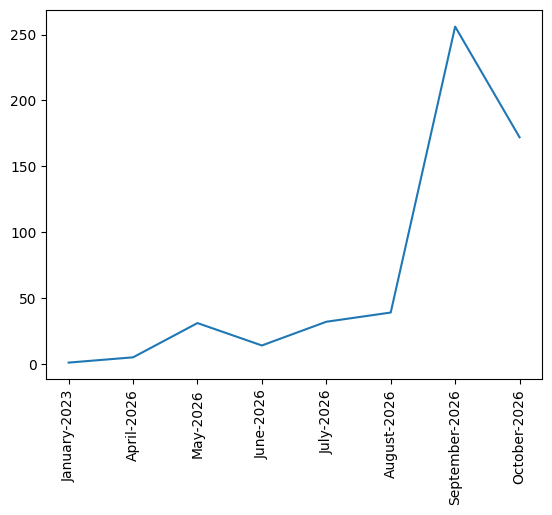

In [71]:
plt.plot(timeline['time'],timeline['message'])
plt.xticks(rotation= 'vertical')
plt.show()

In [74]:
df['only_date'] = df['date'].dt.date

In [82]:
daily_timeline = df.groupby('only_date').count()['message'].reset_index()

(array([19358., 19539., 19723., 19905., 20089., 20270., 20454., 20635.]),
 [Text(19358.0, 0, '2023-01'),
  Text(19539.0, 0, '2023-07'),
  Text(19723.0, 0, '2024-01'),
  Text(19905.0, 0, '2024-07'),
  Text(20089.0, 0, '2025-01'),
  Text(20270.0, 0, '2025-07'),
  Text(20454.0, 0, '2026-01'),
  Text(20635.0, 0, '2026-07')])

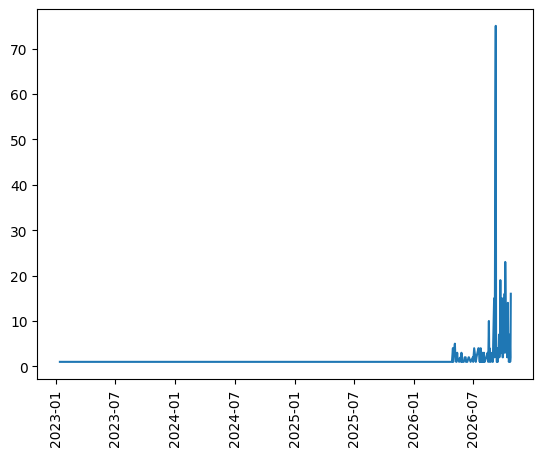

In [84]:
plt.plot(daily_timeline['only_date'], daily_timeline['message'])
plt.xticks(rotation = 'vertical')

In [85]:
daily_timeline


,only_date,message
0,2023-01-14,1
1,2026-04-27,1
2,2026-04-30,4
3,2026-05-01,1
4,2026-05-02,4
...,...,...
100,2026-10-20,2
101,2026-10-21,7
102,2026-10-22,1
103,2026-10-23,2


In [87]:
#konse day me sabse jaiyda chat huiye'

df['day_name'] = df['date'].dt.day_name()

In [89]:
df['day_name'].value_counts()

day_name
Tuesday      128
Monday       105
Saturday      84
Thursday      78
Wednesday     71
Sunday        43
Friday        41
Name: count, dtype: int64

In [93]:
# kon se month me jaiyda chat huiye

df['month'].value_counts().sort()

AttributeError: 'Series' object has no attribute 'sort'